# Q1

In [1]:
def exp_approx(x):
    total = 1.0
    term = 1.0
    for i in range(1, 100):
        term *= x / i
        total += term
    return total

def solve_state(energy, l, r_max, n_steps):
    h = r_max / n_steps
    r_vals = [i * h for i in range(n_steps + 1)]
    u = [0.0] * (n_steps + 1)
    u[0] = 0.0
    u[1] = h ** (l + 1)
    for i in range(1, n_steps):
        r = r_vals[i]
        f = -2.0 * (energy + 1.0 / r - l * (l + 1) / (2.0 * r * r))
        u[i + 1] = 2.0 * u[i] - u[i - 1] + h * h * f * u[i]
    return r_vals, u

def interpolate(r_target, r_vals, u_vals):
    h = r_vals[1] - r_vals[0]
    idx = int(r_target / h)
    if idx >= len(r_vals) - 1:
        return u_vals[-1]
    t = (r_target - r_vals[idx]) / h
    return (1.0 - t) * u_vals[idx] + t * u_vals[idx + 1]

def gauss_laguerre_norm(r_vals, u_vals):
    sqrt2 = 2.0 ** 0.5
    x1 = 2.0 - sqrt2
    x2 = 2.0 + sqrt2
    w1 = (2.0 + sqrt2) / 4.0
    w2 = (2.0 - sqrt2) / 4.0
    u1 = interpolate(x1, r_vals, u_vals)
    u2 = interpolate(x2, r_vals, u_vals)
    g1 = (u1 ** 2) * exp_approx(x1)
    g2 = (u2 ** 2) * exp_approx(x2)
    norm_sq = w1 * g1 + w2 * g2
    return norm_sq ** 0.5

r_max = 20.0
n_steps = 2000

r_vals, u_ground = solve_state(-0.5, 0, r_max, n_steps)
norm_g = gauss_laguerre_norm(r_vals, u_ground)
u_ground_norm = [val / norm_g for val in u_ground]

r_vals, u_excited = solve_state(-0.125, 0, r_max, n_steps)
norm_e = gauss_laguerre_norm(r_vals, u_excited)
u_excited_norm = [val / norm_e for val in u_excited]

print("GROUND STATE (1s, E = -0.5 a.u.):")
print("r\tNumerical\tAnalytical")
for i in range(1, 11):
    r = i * 0.5
    num = interpolate(r, r_vals, u_ground_norm)
    ana = 2.0 * r * exp_approx(-r)
    print(f"{r:.1f}\t{num:.6f}\t{ana:.6f}")

print("\nFIRST EXCITED STATE (2s, E = -0.125 a.u.):")
print("r\tNumerical\tAnalytical")
for i in range(1, 11):
    r = i * 0.5
    num = interpolate(r, r_vals, u_excited_norm)
    ana = (1.0 / (2.0 ** 0.5)) * r * (1.0 - 0.5 * r) * exp_approx(-0.5 * r)
    print(f"{r:.1f}\t{num:.6f}\t{ana:.6f}")

GROUND STATE (1s, E = -0.5 a.u.):
r	Numerical	Analytical
0.5	0.647675	0.606531
1.0	0.785679	0.735759
1.5	0.714822	0.669390
2.0	0.578100	0.541341
2.5	0.438319	0.410425
3.0	0.319057	0.298722
3.5	0.225816	0.211382
4.0	0.156595	0.146525
4.5	0.106945	0.099981
5.0	0.072210	0.067379

FIRST EXCITED STATE (2s, E = -0.125 a.u.):
r	Numerical	Analytical
0.5	0.292060	0.206511
1.0	0.303278	0.214441
1.5	0.177150	0.125255
2.0	0.000010	0.000000
2.5	-0.179060	-0.126618
3.0	-0.334694	-0.236665
3.5	-0.456159	-0.322551
4.0	-0.541348	-0.382786
4.5	-0.592881	-0.419223
5.0	-0.615650	-0.435321


# Plot of 1 Q

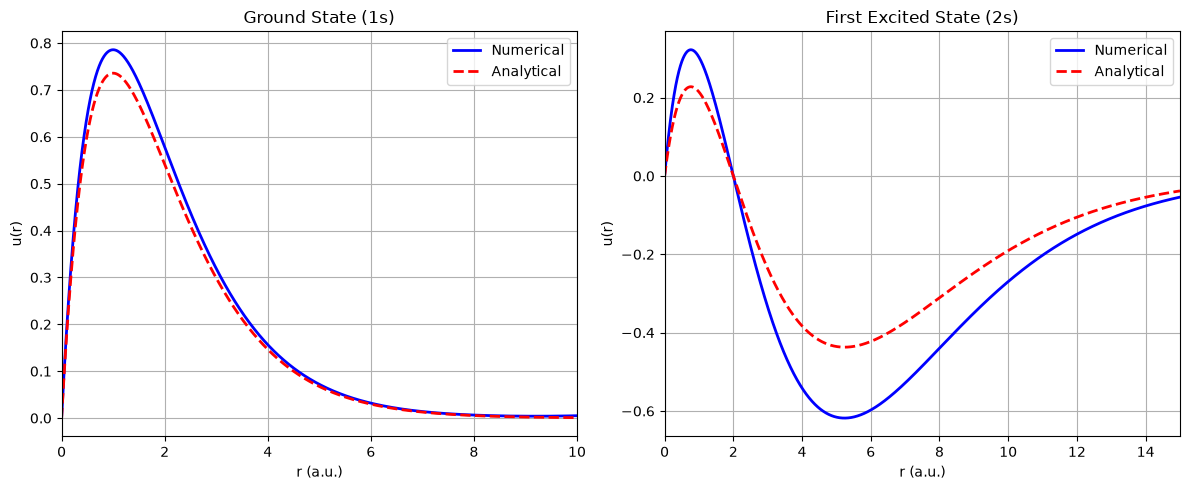

In [2]:
import matplotlib.pyplot as plt

def exp_approx(x):
    total = 1.0
    term = 1.0
    for i in range(1, 100):
        term *= x / i
        total += term
    return total

def solve_state(energy, l, r_max, n_steps):
    h = r_max / n_steps
    r_vals = [i * h for i in range(n_steps + 1)]
    u = [0.0] * (n_steps + 1)
    u[0] = 0.0
    u[1] = h ** (l + 1)
    for i in range(1, n_steps):
        r = r_vals[i]
        f = -2.0 * (energy + 1.0 / r - l * (l + 1) / (2.0 * r * r))
        u[i + 1] = 2.0 * u[i] - u[i - 1] + h * h * f * u[i]
    return r_vals, u

def interpolate(r_target, r_vals, u_vals):
    h = r_vals[1] - r_vals[0]
    idx = int(r_target / h)
    if idx >= len(r_vals) - 1:
        return u_vals[-1]
    t = (r_target - r_vals[idx]) / h
    return (1.0 - t) * u_vals[idx] + t * u_vals[idx + 1]

def gauss_laguerre_norm(r_vals, u_vals):
    sqrt2 = 2.0 ** 0.5
    x1 = 2.0 - sqrt2
    x2 = 2.0 + sqrt2
    w1 = (2.0 + sqrt2) / 4.0
    w2 = (2.0 - sqrt2) / 4.0
    u1 = interpolate(x1, r_vals, u_vals)
    u2 = interpolate(x2, r_vals, u_vals)
    g1 = (u1 ** 2) * exp_approx(x1)
    g2 = (u2 ** 2) * exp_approx(x2)
    return (w1 * g1 + w2 * g2) ** 0.5

r_max = 15.0
n_steps = 3000

r_vals, u_ground = solve_state(-0.5, 0, r_max, n_steps)
norm_g = gauss_laguerre_norm(r_vals, u_ground)
u_ground_norm = [val / norm_g for val in u_ground]
u_ground_ana = [2.0 * r * exp_approx(-r) for r in r_vals]

_, u_excited = solve_state(-0.125, 0, r_max, n_steps)
norm_e = gauss_laguerre_norm(r_vals, u_excited)
u_excited_norm = [val / norm_e for val in u_excited]
u_excited_ana = [(1.0 / (2.0 ** 0.5)) * r * (1.0 - 0.5 * r) * exp_approx(-0.5 * r) for r in r_vals]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(r_vals, u_ground_norm, label="Numerical", color="blue", linewidth=2)
ax1.plot(r_vals, u_ground_ana, label="Analytical", color="red", linestyle="--", linewidth=2)
ax1.set_xlim(0, 10)
ax1.set_xlabel("r (a.u.)")
ax1.set_ylabel("u(r)")
ax1.set_title("Ground State (1s)")
ax1.legend()
ax1.grid(True)

ax2.plot(r_vals, u_excited_norm, label="Numerical", color="blue", linewidth=2)
ax2.plot(r_vals, u_excited_ana, label="Analytical", color="red", linestyle="--", linewidth=2)
ax2.set_xlim(0, 15)
ax2.set_xlabel("r (a.u.)")
ax2.set_ylabel("u(r)")
ax2.set_title("First Excited State (2s)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Q2

Calculated Normalization Constant (N): 0.75113


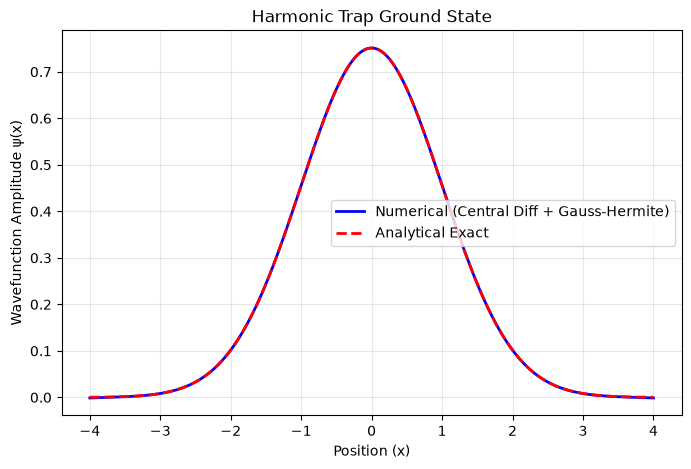

In [6]:
import math
import matplotlib.pyplot as plt

# --- Parameters ---
E = 0.5          # Ground state energy in dimensionless units
h = 0.01         # Spatial step size
x_max = 4.0      # Maximum x value to compute
n_steps = int(x_max / h)

# Initialize arrays
x_vals = [i * h for i in range(n_steps + 1)]
psi = [0.0] * (n_steps + 1)

# --- 1. Central Difference Iteration ---
psi[0] = 1.0  # Arbitrary unnormalized starting value at x=0
# Apply boundary condition psi'(0) = 0 (symmetry)
psi[1] = psi[0] * (1.0 - 0.5 * h**2 * (2.0 * E - x_vals[0]**2))

for i in range(1, n_steps):
    k_sq = 2.0 * E - x_vals[i]**2
    psi[i+1] = (2.0 - h**2 * k_sq) * psi[i] - psi[i-1]

# --- 2. Gauss-Hermite 2-Point Normalization ---
root = 1.0 / math.sqrt(2.0)  # The 2-point positive root
weight = math.sqrt(math.pi) / 2.0

# Interpolate to find psi value exactly at x = 1/sqrt(2)
idx = int(root / h)
x_left, x_right = x_vals[idx], x_vals[idx+1]
psi_left, psi_right = psi[idx], psi[idx+1]
psi_root = psi_left + (psi_right - psi_left) * (root - x_left) / (x_right - x_left)

# f(x) = e^(x^2) * psi(x)^2
f_root = math.exp(root**2) * (psi_root**2)

# Integral = w1*f(-root) + w2*f(root) = 2 * w * f(root) (since symmetric)
integral = 2.0 * weight * f_root
N = 1.0 / math.sqrt(integral)

print(f"Calculated Normalization Constant (N): {N:.5f}")

# Normalize the wavefunction
psi_norm = [N * p for p in psi]

# --- 3. Plotting ---
# Mirror the positive x values to negative for a full plot
x_full = [-x for x in reversed(x_vals[1:])] + x_vals
psi_full = [p for p in reversed(psi_norm[1:])] + psi_norm

# Analytical ground state for comparison: pi^(-1/4) * exp(-x^2 / 2)
analytical = [math.pi**(-0.25) * math.exp(-0.5 * x**2) for x in x_full]

plt.figure(figsize=(8, 5))
plt.plot(x_full, psi_full, label='Numerical (Central Diff + Gauss-Hermite)', color='blue', linewidth=2)
plt.plot(x_full, analytical, label='Analytical Exact', color='red', linestyle='--', linewidth=2)
plt.xlabel('Position (x)')
plt.ylabel('Wavefunction Amplitude \u03C8(x)')
plt.title('Harmonic Trap Ground State')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 3D Visualization

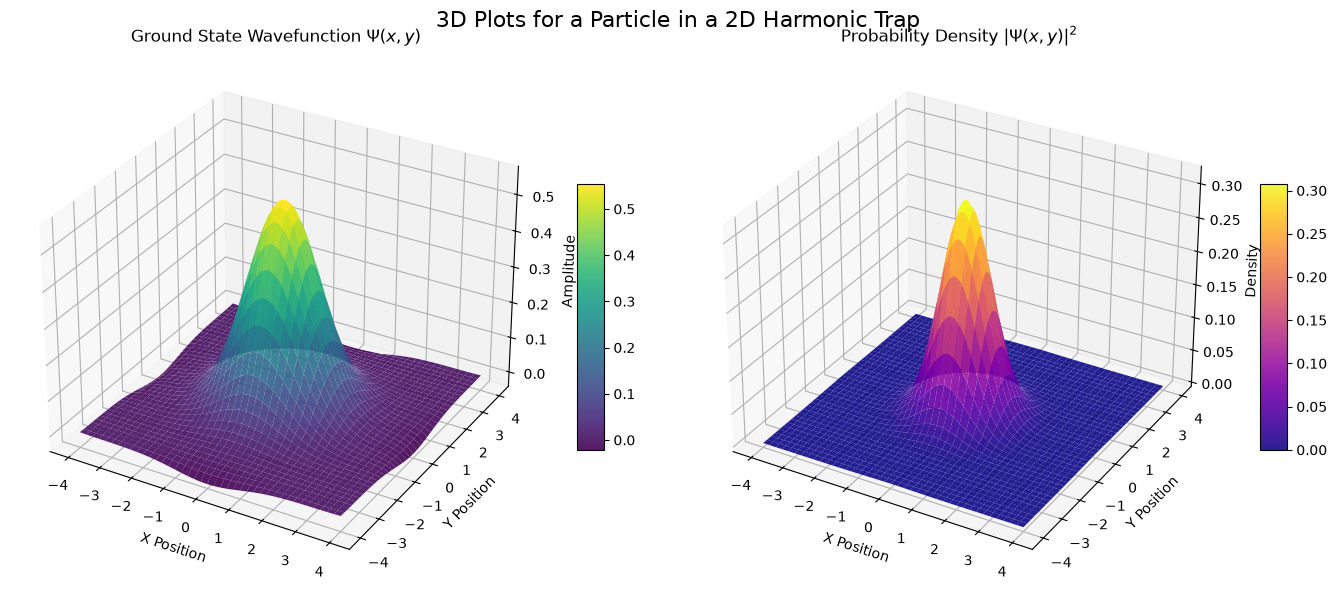

In [7]:
import math
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Compute the 1D Numerical Solution ---
E = 0.5
h = 0.05  # Step size (slightly larger for smoother 3D surface rendering)
x_max = 4.0
n_steps = int(x_max / h)

x_vals = [i * h for i in range(n_steps + 1)]
psi = [0.0] * (n_steps + 1)

# Central Difference Iteration
psi[0] = 1.0
psi[1] = psi[0] * (1.0 - 0.5 * h**2 * (2.0 * E - x_vals[0]**2))

for i in range(1, n_steps):
    k_sq = 2.0 * E - x_vals[i]**2
    psi[i+1] = (2.0 - h**2 * k_sq) * psi[i] - psi[i-1]

# Gauss-Hermite 2-Point Normalization
root = 1.0 / math.sqrt(2.0)
weight = math.sqrt(math.pi) / 2.0
idx = int(root / h)

# Interpolate at x = 1/sqrt(2)
x_left, x_right = x_vals[idx], x_vals[idx+1]
psi_left, psi_right = psi[idx], psi[idx+1]
psi_root = psi_left + (psi_right - psi_left) * (root - x_left) / (x_right - x_left)

f_root = math.exp(root**2) * (psi_root**2)
integral = 2.0 * weight * f_root
N = 1.0 / math.sqrt(integral)

# Mirror to get full -x to +x range
psi_norm = [N * p for p in psi]
x_full = [-x for x in reversed(x_vals[1:])] + x_vals
psi_full = [p for p in reversed(psi_norm[1:])] + psi_norm


# --- 2. Construct 2D Data for 3D Plotting ---
# Convert to numpy arrays for the 3D surface plot requirements
X, Y = np.meshgrid(x_full, x_full)

# The 2D ground state wavefunction is the outer product of the 1D solutions
Z_wavefunction = np.outer(psi_full, psi_full)

# Probability density is the square of the wavefunction
Z_probability = Z_wavefunction**2


# --- 3. Plot the 3D Surfaces ---
fig = plt.figure(figsize=(14, 6))

# First Plot: Wavefunction
ax1 = fig.add_subplot(121, projection='3d')
surf1 = ax1.plot_surface(X, Y, Z_wavefunction, cmap='viridis', edgecolor='none', alpha=0.9)
ax1.set_title('Ground State Wavefunction $\Psi(x,y)$')
ax1.set_xlabel('X Position')
ax1.set_ylabel('Y Position')
ax1.set_zlabel('Amplitude')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

# Second Plot: Probability Density
ax2 = fig.add_subplot(122, projection='3d')
surf2 = ax2.plot_surface(X, Y, Z_probability, cmap='plasma', edgecolor='none', alpha=0.9)
ax2.set_title('Probability Density $|\Psi(x,y)|^2$')
ax2.set_xlabel('X Position')
ax2.set_ylabel('Y Position')
ax2.set_zlabel('Density')
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

plt.suptitle('3D Plots for a Particle in a 2D Harmonic Trap', fontsize=16)
plt.tight_layout()
plt.show()

# Q3

Enter a range of b values separated by commas (e.g., 0.1, 0.2, 0.3):  0.22


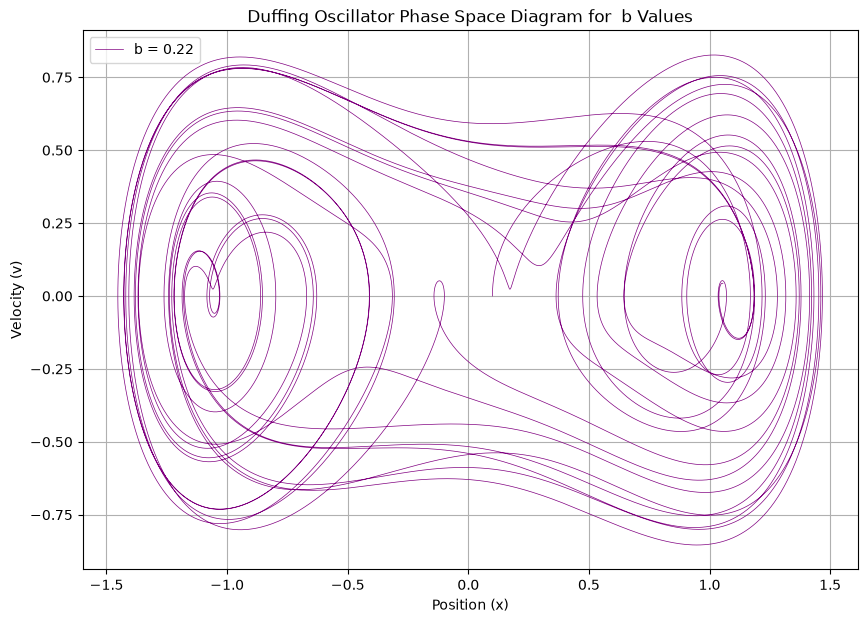

In [3]:
import matplotlib.pyplot as plt

def cos_approx(x):
    pi_val = 3.141592653589793
    x = x % (2 * pi_val)
    total = 1.0
    term = 1.0
    for i in range(1, 30):
        term *= -x * x / ((2 * i - 1) * (2 * i))
        total += term
    return total

b_input = input("Enter a range of b values separated by commas (e.g., 0.1, 0.2, 0.3): ")
if b_input.strip():
    b_values = [float(val.strip()) for val in b_input.split(',')]
else:
    b_values = [0.1, 0.2, 0.3]

k = -1.0
l = 1.0
m = 1.0
F0 = 0.3
omega = 1.2

dt = 0.01
t_max = 200.0
steps = int(t_max / dt)

def f1(t, x, v):
    return v

def f2(t, x, v, b_val):
    return (-k * x - l * (x ** 3) - b_val * v + F0 * cos_approx(omega * t)) / m

plt.figure(figsize=(10, 7))

colors = ['purple', 'blue', 'green', 'red', 'orange', 'cyan', 'brown']

for idx, b in enumerate(b_values):
    t = 0.0
    x = 0.1
    v = 0.0

    x_vals = []
    v_vals = []

    for _ in range(steps):
        x_vals.append(x)
        v_vals.append(v)

        k1_x = f1(t, x, v)
        k1_v = f2(t, x, v, b)

        k2_x = f1(t + 0.5 * dt, x + 0.5 * dt * k1_x, v + 0.5 * dt * k1_v)
        k2_v = f2(t + 0.5 * dt, x + 0.5 * dt * k1_x, v + 0.5 * dt * k1_v, b)

        k3_x = f1(t + 0.5 * dt, x + 0.5 * dt * k2_x, v + 0.5 * dt * k2_v)
        k3_v = f2(t + 0.5 * dt, x + 0.5 * dt * k2_x, v + 0.5 * dt * k2_v, b)

        k4_x = f1(t + dt, x + dt * k3_x, v + dt * k3_v)
        k4_v = f2(t + dt, x + dt * k3_x, v + dt * k3_v, b)

        x += (dt / 6.0) * (k1_x + 2 * k2_x + 2 * k3_x + k4_x)
        v += (dt / 6.0) * (k1_v + 2 * k2_v + 2 * k3_v + k4_v)
        t += dt

    c = colors[idx % len(colors)]
    plt.plot(x_vals, v_vals, color=c, linewidth=0.5, label=f"b = {b}")

plt.title("Duffing Oscillator Phase Space Diagram for  b Values")
plt.xlabel("Position (x)")
plt.ylabel("Velocity (v)")
plt.legend()
plt.grid(True)
plt.show()

# Q4

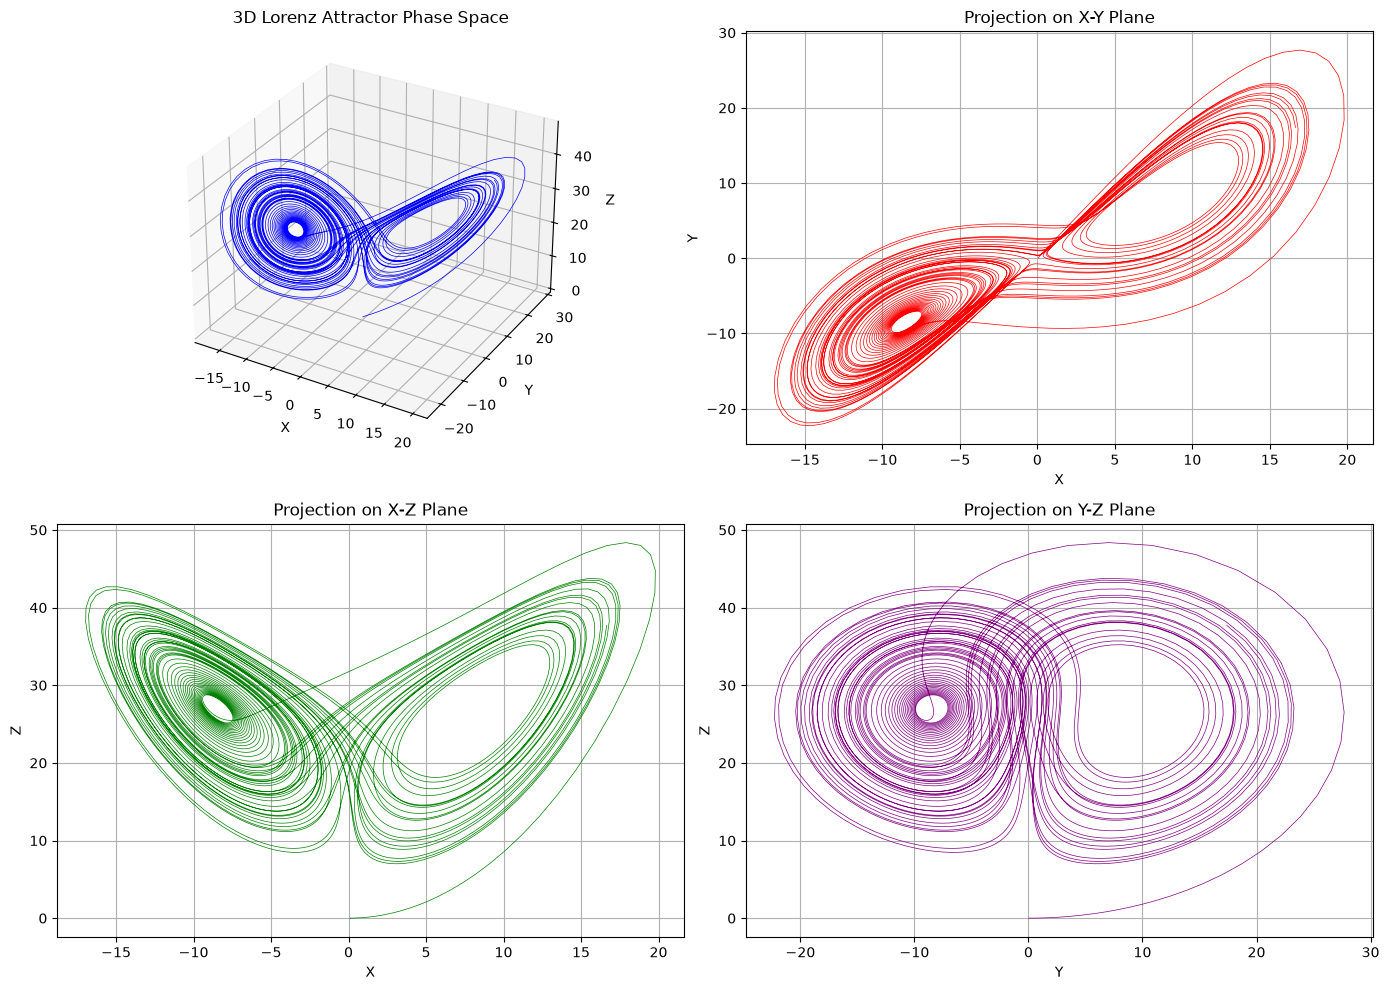

In [4]:
import matplotlib.pyplot as plt

# Parameters for the Lorenz Attractor
sigma = 10.0
rho = 28.0
beta = 2.66

# Time step and duration
dt = 0.01
t_max = 50.0
steps = int(t_max / dt)

# Initial conditions
x = 0.1
y = 0.0
z = 0.0

# Lists to store the trajectory
x_vals = [x]
y_vals = [y]
z_vals = [z]

# Differential equations
def f_x(x, y, z):
    return sigma * (y - x)

def f_y(x, y, z):
    return x * (rho - z) - y

def f_z(x, y, z):
    return x * y - beta * z

# 4th Order Runge-Kutta (RK4) Integration
for _ in range(steps):
    k1_x = f_x(x, y, z)
    k1_y = f_y(x, y, z)
    k1_z = f_z(x, y, z)

    k2_x = f_x(x + 0.5 * dt * k1_x, y + 0.5 * dt * k1_y, z + 0.5 * dt * k1_z)
    k2_y = f_y(x + 0.5 * dt * k1_x, y + 0.5 * dt * k1_y, z + 0.5 * dt * k1_z)
    k2_z = f_z(x + 0.5 * dt * k1_x, y + 0.5 * dt * k1_y, z + 0.5 * dt * k1_z)

    k3_x = f_x(x + 0.5 * dt * k2_x, y + 0.5 * dt * k2_y, z + 0.5 * dt * k2_z)
    k3_y = f_y(x + 0.5 * dt * k2_x, y + 0.5 * dt * k2_y, z + 0.5 * dt * k2_z)
    k3_z = f_z(x + 0.5 * dt * k2_x, y + 0.5 * dt * k2_y, z + 0.5 * dt * k2_z)

    k4_x = f_x(x + dt * k3_x, y + dt * k3_y, z + dt * k3_z)
    k4_y = f_y(x + dt * k3_x, y + dt * k3_y, z + dt * k3_z)
    k4_z = f_z(x + dt * k3_x, y + dt * k3_y, z + dt * k3_z)

    x += (dt / 6.0) * (k1_x + 2 * k2_x + 2 * k3_x + k4_x)
    y += (dt / 6.0) * (k1_y + 2 * k2_y + 2 * k3_y + k4_y)
    z += (dt / 6.0) * (k1_z + 2 * k2_z + 2 * k3_z + k4_z)

    x_vals.append(x)
    y_vals.append(y)
    z_vals.append(z)

# Plotting the results (3D full view and 2D projections)
fig = plt.figure(figsize=(14, 10))

# 1. 3D Plot
ax1 = fig.add_subplot(221, projection='3d')
ax1.plot(x_vals, y_vals, z_vals, color='blue', linewidth=0.5)
ax1.set_title("3D Lorenz Attractor Phase Space")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

# 2. X-Y Plane Plot
ax2 = fig.add_subplot(222)
ax2.plot(x_vals, y_vals, color='red', linewidth=0.5)
ax2.set_title("Projection on X-Y Plane")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.grid(True)

# 3. X-Z Plane Plot
ax3 = fig.add_subplot(223)
ax3.plot(x_vals, z_vals, color='green', linewidth=0.5)
ax3.set_title("Projection on X-Z Plane")
ax3.set_xlabel("X")
ax3.set_ylabel("Z")
ax3.grid(True)

# 4. Y-Z Plane Plot
ax4 = fig.add_subplot(224)
ax4.plot(y_vals, z_vals, color='purple', linewidth=0.5)
ax4.set_title("Projection on Y-Z Plane")
ax4.set_xlabel("Y")
ax4.set_ylabel("Z")
ax4.grid(True)

plt.tight_layout()
plt.show()